## Note this is a quadratic function algorithm

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Initialize as floats
point = np.array([1.0, 5.0])

# A-conjugate directions (p0.T @ H @ p1 == 0)
directions = [np.array([1.0, 0.0]), np.array([0.0, 1.0])]

tol = 1e-6
k = 0
max_iter = len(directions)


def f(x, y):
  return (x - 3) ** 2 + 2 * (y - 2) ** 2


def gradient(x, y):
  df_dx = 2 * x - 6
  df_dy = 4 * y - 8
  return np.array([df_dx, df_dy])


def hessian():
  return np.array([[2.0, 0.0], [0.0, 4.0]])

history_of_x = [point[0]]
history_of_y = [point[1]]
history_of_z = [f(point[0], point[1])]

while np.linalg.norm(gradient(point[0], point[1])) > tol and k < max_iter:
  grad = gradient(point[0], point[1])
  p = directions[k]
  H = hessian()

  # Use @ for proper dot/matrix multiplication to get a scalar
  alpha_k = -(grad.T @ p) / (p.T @ H @ p)

  # Update position
  point = point + (alpha_k * p)
  k += 1

  history_of_x.append(point[0])
  history_of_y.append(point[1])
  history_of_z.append(f(point[0], point[1]))

  print(f'Current Height: {f(point[0], point[1]):.4f}, Current Points: {point}, Epoch: {k}')


Current Height: 18.0000, Current Points: [3. 5.], Epoch: 1
Current Height: 0.0000, Current Points: [3. 2.], Epoch: 2


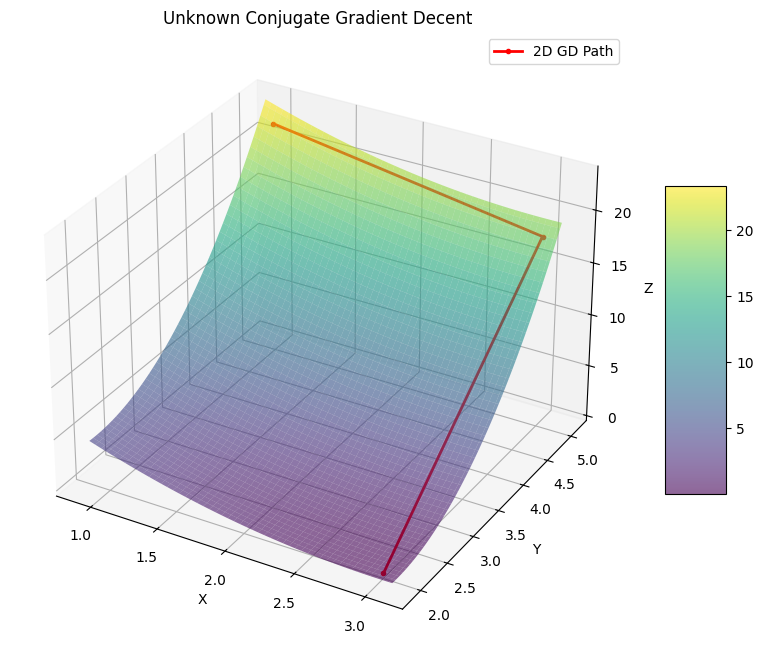

In [6]:
X_surf = np.linspace(min(history_of_x)-0.1, max(history_of_x)+0.1, 100)
Y_surf = np.linspace(min(history_of_y)-0.1, max(history_of_y)+0.1, 100)
X,Y = np.meshgrid(X_surf, Y_surf)
Z = f(X,Y)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(X,Y,Z, cmap='viridis', alpha=0.6)
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5, label='')

ax.plot(history_of_x, history_of_y, history_of_z, color = 'Red', marker='.', linewidth = 2,label='2D GD Path')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Unknown Conjugate Gradient Decent')
ax.legend()
plt.show()

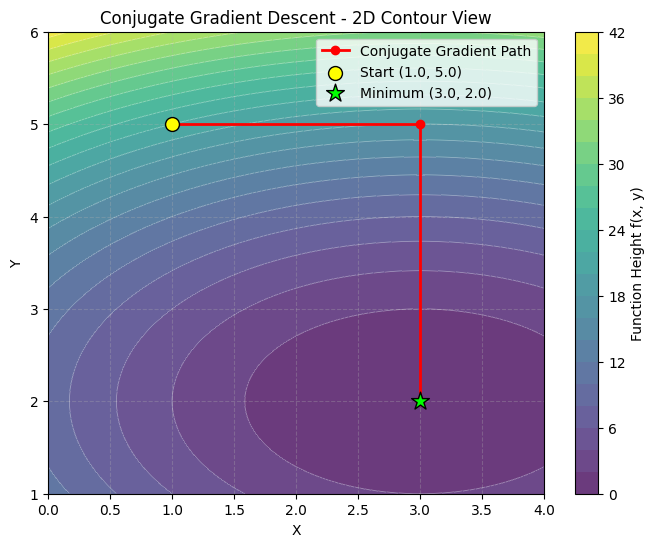

In [7]:
# Widen the grid padding slightly (e.g., 1.0 instead of 0.1) so the ellipses frame the path cleanly
X_surf = np.linspace(min(history_of_x) - 1.0, max(history_of_x) + 1.0, 200)
Y_surf = np.linspace(min(history_of_y) - 1.0, max(history_of_y) + 1.0, 200)
X, Y = np.meshgrid(X_surf, Y_surf)
Z = f(X, Y)

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Draw filled contours and contour lines
contour_filled = ax.contourf(X, Y, Z, levels=25, cmap='viridis', alpha=0.8)
contour_lines = ax.contour(X, Y, Z, levels=25, colors='white', linewidths=0.6, alpha=0.5)
fig.colorbar(contour_filled, ax=ax, label='Function Height f(x, y)')

# 2. Plot the 2D optimization path (no Z values needed here)
ax.plot(history_of_x, history_of_y, color='red', marker='o', markersize=6, linewidth=2, label='Conjugate Gradient Path')

# 3. Highlight the start and end points
ax.scatter(history_of_x[0], history_of_y[0], color='yellow', edgecolor='black', s=100, zorder=5, label='Start (1.0, 5.0)')
ax.scatter(history_of_x[-1], history_of_y[-1], color='lime', edgecolor='black', marker='*', s=180, zorder=5, label='Minimum (3.0, 2.0)')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Conjugate Gradient Descent - 2D Contour View')
ax.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()
